# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [ ]:
%%writefile heap.py
import matplotlib.pyplot as plt


class Heap:
    """Min heap con las convenciones de la página de Galles:
    arreglo[0] = -inf (centinela), raíz en 1, hijos de i en 2*i y 2*i+1."""

    def __init__(self):
        self.arreglo = [float('-inf')]

    # ---------- utilidades internas ----------
    def _subir(self, i):
        # sube mientras el padre sea estrictamente mayor
        while self.arreglo[i // 2] > self.arreglo[i]:
            self.arreglo[i // 2], self.arreglo[i] = self.arreglo[i], self.arreglo[i // 2]
            i //= 2

    def _bajar(self, i):
        n = len(self.arreglo) - 1
        while 2 * i <= n:
            menor = 2 * i
            # el hijo derecho solo gana si es estrictamente menor
            if menor + 1 <= n and self.arreglo[menor + 1] < self.arreglo[menor]:
                menor += 1
            if self.arreglo[menor] < self.arreglo[i]:
                self.arreglo[i], self.arreglo[menor] = self.arreglo[menor], self.arreglo[i]
                i = menor
            else:
                break

    # ---------- operaciones de la página ----------
    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        self._subir(len(self.arreglo) - 1)
        if imagen:
            self._mostrar()

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) == 1:
            if imagen:
                self._mostrar()
            return None
        minimo = self.arreglo[1]
        ultimo = self.arreglo.pop()
        if len(self.arreglo) > 1:
            self.arreglo[1] = ultimo
            self._bajar(1)
        if imagen:
            self._mostrar()
        return minimo

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        for i in range((len(self.arreglo) - 1) // 2, 0, -1):
            self._bajar(i)
        if imagen:
            self._mostrar()

    # ---------- imagen del árbol ----------
    def _mostrar(self):
        n = len(self.arreglo) - 1
        fig, ax = plt.subplots(figsize=(max(4, n * 0.35), 4))
        ax.axis('off')
        if n == 0:
            ax.text(0.5, 0.5, 'Heap vacío', ha='center', va='center')
            plt.show()
            return

        niveles = n.bit_length()               # número de niveles
        pos = {}
        for i in range(1, n + 1):
            d = i.bit_length() - 1             # nivel (raíz = 0)
            j = i - 2 ** d                     # lugar dentro del nivel
            pos[i] = ((j + 0.5) / 2 ** d, -d)  # izquierda a derecha, raíz arriba

        for i in range(2, n + 1):              # aristas padre -> hijo
            (x1, y1), (x2, y2) = pos[i // 2], pos[i]
            ax.plot([x1, x2], [y1, y2], color='gray', zorder=1)

        for i in range(1, n + 1):              # nodos (sin el -inf de la posición 0)
            x, y = pos[i]
            ax.text(x, y, str(self.arreglo[i]), ha='center', va='center', zorder=2,
                    bbox=dict(boxstyle='circle,pad=0.35', fc='lightblue', ec='black'))

        ax.set_xlim(0, 1)
        ax.set_ylim(-niveles + 0.4, 0.6)
        plt.show()


if __name__ == "__main__":
    H = Heap()
    H.insert(10)
    H.insert(4)
    H.insert(7, imagen=True)
    H.remove_smallest(imagen=True)
    H.build_heap(list(range(31, 0, -1)), imagen=True)
    print(H.arreglo)

Overwriting heap.py


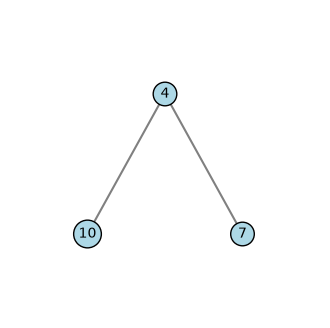

In [3]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)